# Scaling images

A table's columns are different measurements, each in its own units, so [Scaling numerical features](../feature_scaling.ipynb) scales each column on its own. An image is many measurements of the same thing, the brightness of a point, in the same units everywhere. That changes how it should be scaled.

## Two ways of standardising

For a dataset of $N$ rows and $D$ columns, with $x_{ij}$ the value of column $j$ in row $i$:

- **Per feature**, as `StandardScaler` does: each column $j$ gets its own mean $\mu_j$ and standard deviation $\sigma_j$, and $x'_{ij} = (x_{ij} - \mu_j) / \sigma_j$. Every column ends with mean 0 and standard deviation 1.
- **Global**: one mean $\mu$ and one standard deviation $\sigma$, computed over all the $N \times D$ values, and $x'_{ij} = (x_{ij} - \mu) / \sigma$. The whole dataset ends with mean 0 and standard deviation 1, and the columns keep their sizes relative to each other.

## A table: each column on its own

In [ ]:
import numpy as np
import pandas as pd

people = pd.DataFrame({"age": [25, 62, 26, 41], "income": [30_000, 30_500, 33_000, 52_000]})
pd.concat({
    "per feature": (people - people.mean()) / people.std(),
    "global": (people - people.stack().mean()) / people.stack().std(),
}, axis=1).round(3)

per feature        global       
          age income    age income
0      -0.781 -0.607 -0.882  0.572
1       1.359 -0.560 -0.881  0.597
2      -0.723 -0.321 -0.882  0.718
3       0.145  1.488 -0.882  1.640

With one mean and standard deviation for both columns, the incomes, in the tens of thousands, decide both statistics, and the four ages all become −0.88: their differences, 37 years among them, are gone. A table's columns are not comparable numbers, so they must be scaled one by one.

## An image: one scale for every pixel

scikit-learn's digits: 1,797 handwritten digits of 8 × 8 pixels, each pixel a brightness from 0 (white) to 16 (black), bundled with the library. As a table, each image is a row of 64 pixel columns:

In [ ]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train.shape, X_train.min(), X_train.max()

((1437, 64), np.float64(0.0), np.float64(16.0))

One training image, standardised globally (one mean and standard deviation for all pixels) and per pixel (`StandardScaler`, one for each of the 64 positions):

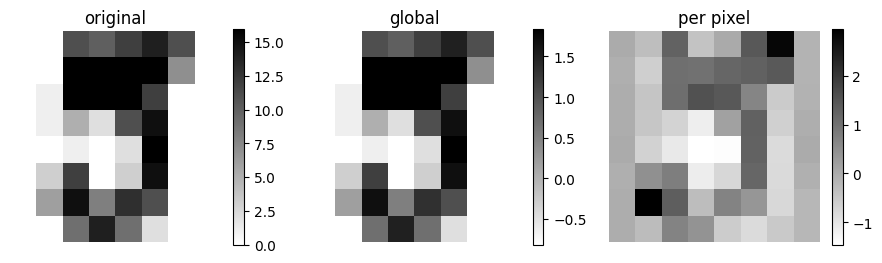

In [ ]:
import matplotlib.pyplot as plt

global_mean, global_std = X_train.mean(), X_train.std()
per_pixel = StandardScaler().fit(X_train)
image = X_train[:1]
versions = {
    "original": image,
    "global": (image - global_mean) / global_std,
    "per pixel": per_pixel.transform(image),
}
figure, axes = plt.subplots(1, 3, figsize=(9, 3))
for axis, (name, version) in zip(axes, versions.items()):
    shown = axis.imshow(version.reshape(8, 8), cmap="gray_r")
    figure.colorbar(shown, ax=axis, shrink=0.8)
    axis.set_title(name)
    axis.set_axis_off()
figure.tight_layout()

Global standardisation gives the same picture: only the numbers on the scale change, the same for every pixel. Per-pixel standardisation gives a different picture: each position has its own scale, so the same ink is a different number in different places. A pixel near the edge, almost always blank, has a tiny standard deviation, and the rare stroke that reaches it becomes enormous:

In [ ]:
per_pixel_values = per_pixel.transform(X_train)
pd.Series({
    "largest value after per-pixel scaling": f"{np.abs(per_pixel_values).max():.1f}",
    "pixels that are blank in every training image": f"{(X_train.std(axis=0) == 0).sum()}",
})

largest value after per-pixel scaling            37.9
pixels that are blank in every training image       3
dtype: str

A stroke 38 standard deviations away: in a table, an outlier; in an image, a little ink near the edge. (Pixels blank in every image have no variation at all; `StandardScaler` leaves them at 0.)

## Convolutional networks

A convolutional network slides the same small filter over every position of the image, looking for the same pattern (an edge, a curve) everywhere. That only works if a value means the same brightness at every position, which per-pixel scaling breaks. So images for these networks are scaled with one mean and standard deviation for all the pixels of the training images, or one per colour channel: in PyTorch's `torchvision`, `transforms.Normalize(mean, std)` takes one value per channel (red, green and blue), never one per pixel.

The values most often seen, `mean=[0.485, 0.456, 0.406]` and `std=[0.229, 0.224, 0.225]`, are the statistics of the ImageNet photos, on brightness already divided by 255; they map the pixels to roughly −2.1 to 2.6. They are used with the models pretrained on ImageNet because a pretrained model expects its inputs scaled as during its training: when reusing one, use the statistics it was trained with, not those of your own images. Neural networks *(coming)* trains convolutional networks; the exercises of [numpy-mnist](https://github.com/avidaldo/numpy-mnist) standardise images by hand, without leaking.

## Flattened images in other models

Models that take an image as a row of pixel columns (k-nearest neighbours, support vector machines, logistic regression, a network without convolutions) know nothing of positions: for them, each pixel is just a column. Per-pixel scaling no longer breaks anything they rely on, but does it help? The raw pixels, the pixels divided by 16 (the maximum brightness, a fixed rule that learns nothing), and per-pixel standardisation, by 5-fold cross-validation:

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import SVC

def divide_by_16(pixels):
    return pixels / 16


scalings = {
    "raw": "passthrough",
    "divided by 16": FunctionTransformer(divide_by_16),
    "per pixel": StandardScaler(),
}
models = {
    "k-nearest neighbours": KNeighborsClassifier(),
    "support vector machine": SVC(),
    "logistic regression": LogisticRegression(max_iter=5000),
}
pd.DataFrame({
    scaling_name: {model_name: cross_val_score(make_pipeline(scaling, model), X_train, y_train, cv=5).mean()
                   for model_name, model in models.items()}
    for scaling_name, scaling in scalings.items()
}).round(3)

,raw,divided by 16,per pixel
k-nearest neighbours,0.987,0.987,0.975
support vector machine,0.988,0.988,0.983
logistic regression,0.960,0.962,0.970


- **k-nearest neighbours and the support vector machine** give the same accuracy raw and divided by 16: dividing every pixel by the same number divides every distance by the same number, so the nearest neighbours are the same, and the SVM's default kernel width adapts to the scale of the data. Per-pixel standardisation is slightly *worse* for both: it inflates the rare strokes at the edges, which then weigh heavily in the distances.
- **Logistic regression** is slightly better with per-pixel standardisation, which helps its optimiser and its penalty treat the pixels evenly ([Gradient descent](../../supervised-learning/ml-fundamentals/gradient_descent.ipynb), [Regularisation](../../supervised-learning/ml-fundamentals/regularization.ipynb)).

So there is no rule that flattened images must be standardised per pixel: dividing by the maximum brightness is safe for every model, and anything more is a choice to measure. Rows that should be compared by their proportions rather than their sizes, such as word counts, are a different case again, for `Normalizer` ([Scaling numerical features](../feature_scaling.ipynb#scaling-rows-normalizer-deep-dive)).